# Bayesian Inference and Causal Reasoning

Bayesian inference is a statistical method that allows us to update our beliefs about a hypothesis based on new evidence. It is grounded in Bayes' theorem, which provides a mathematical framework for combining prior knowledge with observed data.

This section will help you to:

1. Apply Bayes' theorem to update a hypothesis after observing evidence.
2. Explain and calculate the prior, likelihood, evidence, and posterior.
3. Build and interpret a Naïve Bayes classifier.
4. Use log probabilities and Laplace smoothing correctly.
5. Distinguish association, prediction, and causation.
6. Recognize confounding and evaluate a causal claim.

## 0. Environment Setup


In [141]:
import warnings

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.naive_bayes import MultinomialNB

# Fix the seed so that simulated results are reproducible.
SEED = 42
rng = np.random.default_rng(SEED)

NAVY = "#0B2E6D"
ORANGE = "#C65A00"
TEAL = "#008C95"
RED = "#D34841"
LIGHT_BLUE = "#DCEAF7"

plt.rcParams.update({
    "figure.figsize": (8.5, 4.8),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

warnings.filterwarnings("ignore", category=UserWarning)


print("Environment ready for this notebook.")

Environment ready for this notebook.


# 1. Bayesian Problem Solving

Bayesian problem solving updates an initial belief after new evidence becomes available:

$$
P(H\mid D)=\frac{P(D\mid H)P(H)}{P(D)}.
$$

The general workflow is **define the problem → identify hypotheses → assign priors → collect evidence → update probabilities → decide or act**.


## Identify the Four Components

> **Problem description.** A medical condition affects 1% of a population. A diagnostic test returns positive for 92% of people who have the condition and for 4% of people who do not. One person receives a positive result.


### Here are the four components of Bayes' theorem for this problem:

1. **Hypothesis:** *$H$: The person has a medical condition.*
2. **Evidence:** *$D$: The person receives a positive test result.*
3. **Prior:** *$P(H)$: 1% of population affected by the medical condition.*
4. **Likelihood:** *$P(D\mid H)$: 92% of people received a positive test result if they are having the condition.*
5. **False-positive probability:** *$P(D\mid\neg H)$: 4% of people received a positive test result if they are not having the condition.*
6. **Desired posterior:** *$P(H\mid D)$: The probability that a person has a medical condition knowing they received a positive result*

**Explanation:** ($P(D\mid H)$) and ($P(H\mid D)$) are not interchangeable because they represent completely different conditional probabilities, hence having a completely different results.


## 2. Fault Detection with Bayes' Theorem

> **Problem description.** A factory uses a diagnostic test to screen devices. The fault rate is 2%, the test detects 95% of faulty devices, and 5% of non-faulty devices incorrectly test positive. For a device with a positive test, calculate the probability that it is actually faulty.

Use:

$$
P(+)=P(+\mid F)P(F)+P(+\mid\neg F)P(\neg F)
$$

and then:

$$
P(F\mid +)=\frac{P(+\mid F)P(F)}{P(+)}.
$$


In [142]:
def bayes_update(prior: float, sensitivity: float, false_positive_rate: float) -> dict:
    """Calculate the posterior probability after a positive test result.

    Parameters
    ----------
    prior:
        Prior probability P(F).
    sensitivity:
        Probability P(+|F), also known as sensitivity.
    false_positive_rate:
        Probability P(+|not F), the false-positive rate.

    Returns
    -------
    dict
        The components of the Bayesian update.
    """

    values = (prior, sensitivity, false_positive_rate)
    if not all(0 <= value <= 1 for value in values):
        raise ValueError("All probabilities must be in the interval [0, 1].")

    evidence = sensitivity * prior + false_positive_rate * (1 - prior)
    if evidence == 0:
        raise ValueError("The evidence is zero, so the posterior is undefined.")

    posterior = sensitivity * prior / evidence
    return {
        "Prior P(F)": prior,
        "Likelihood P(+|F)": sensitivity,
        "Evidence P(+)": evidence,
        "Posterior P(F|+)": posterior,
    }

In [143]:
# Apply Bayes' theorem to a simple fault detection example.
prior_fault = 0.02
sensitivity = 0.95
false_positive_rate = 0.05

bayes_result = bayes_update(prior_fault, sensitivity, false_positive_rate)

print("Prior P(F) =", bayes_result["Prior P(F)"])
print("Likelihood P(+|F) =", bayes_result["Likelihood P(+|F)"])
print("Evidence P(+) =", bayes_result["Evidence P(+)"])
print("P(F | +) =", bayes_result["Posterior P(F|+)"])

Prior P(F) = 0.02
Likelihood P(+|F) = 0.95
Evidence P(+) = 0.068
P(F | +) = 0.2794117647058823


In [144]:
fault_table = pd.DataFrame(
    {"Component": bayes_result.keys(), "Value": bayes_result.values()}
)
fault_table["Percentage"] = fault_table["Value"].map(lambda x: f"{x:.2%}")
display(fault_table.style.format({"Value": "{:.4f}"}))

print(f"Conclusion: P(F|+) = {bayes_result['Posterior P(F|+)']:.4f} "
      f"= {bayes_result['Posterior P(F|+)']:.2%}")

,Component,Value,Percentage
0,Prior P(F),0.0200,2.00%
1,Likelihood P(+|F),0.9500,95.00%
2,Evidence P(+),0.0680,6.80%
3,Posterior P(F|+),0.2794,27.94%


Conclusion: P(F|+) = 0.2794 = 27.94%


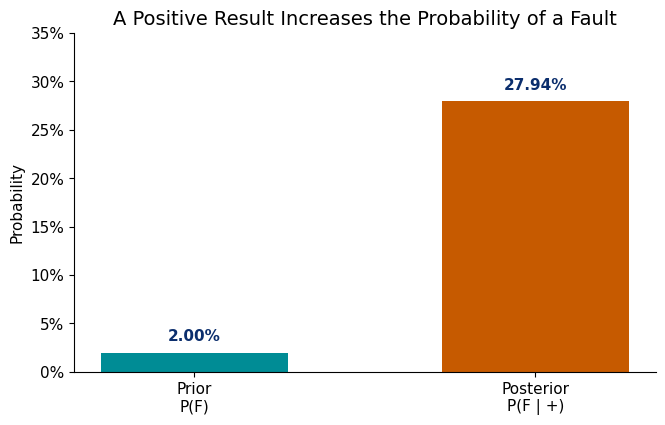

In [145]:
# Visually compare beliefs before and after observing a positive result.
labels = ["Prior\nP(F)", "Posterior\nP(F | +)"]
values = [bayes_result["Prior P(F)"], bayes_result["Posterior P(F|+)"]]

fig, ax = plt.subplots(figsize=(7.5, 4.4))
bars = ax.bar(labels, values, color=[TEAL, ORANGE], width=0.55)
ax.set_ylim(0, 0.35)
ax.set_ylabel("Probability")
ax.set_title("A Positive Result Increases the Probability of a Fault")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")

for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.012,
            f"{value:.2%}", ha="center", color=NAVY, fontweight="bold")

plt.show()

### Interpretation

The posterior is much lower than the test sensitivity of 95% because the base rate of faulty devices is extremely low (2%). Even though the test is highly sensitive, the small number of true faults is outnumbered by false positives from the much larger pool of non-faulty devices (98%).

## 3. Interpret the Test with 10,000 Devices

> **Problem description.** Apply the same fault rate and test accuracy to a hypothetical batch of 10,000 devices. Determine the expected numbers of true positives and false positives, then recover ($P(F\mid+)$) from those counts.


In [146]:
n_devices = 10_000

# Calculate each expected count.
n_faulty = 0.02 * n_devices
n_non_faulty = n_devices - n_faulty
true_positives = 0.95 * n_faulty
false_positives = 0.05 * n_non_faulty
all_positive_results = true_positives + false_positives
fraction_true_among_positive = true_positives / all_positive_results

count_table = pd.DataFrame({
    "Quantity": [
        "Faulty devices",
        "Non-faulty devices",
        "True positives",
        "False positives",
        "All positive results",
    ],
    "Expected count": [
        n_faulty,
        n_non_faulty,
        true_positives,
        false_positives,
        all_positive_results,
    ],
})
display(count_table.style.format({"Expected count": "{:,.0f}"}))
print("Fraction of positive results that are true positives:", fraction_true_among_positive)

,Quantity,Expected count
0,Faulty devices,200
1,Non-faulty devices,"9,800"
2,True positives,190
3,False positives,490
4,All positive results,680


Fraction of positive results that are true positives: 0.27941176470588236


In [147]:
# The following table summarizes the expected counts of devices and positive results.
table_10000 = pd.DataFrame({
    "Group": ["Faulty devices", "Non-faulty devices", "All positive results"],
    "Number of devices": [n_faulty, n_non_faulty, n_devices],
    "Positive results": [true_positives, false_positives, true_positives + false_positives],
})
display(table_10000.style.format({
    "Number of devices": "{:,.0f}",
    "Positive results": "{:,.0f}",
}))

print(
    f"Among {true_positives + false_positives:,.0f} positive results, only "
    f"{true_positives:,.0f} are true positives → "
    f"{true_positives / (true_positives + false_positives):.2%}."
)

,Group,Number of devices,Positive results
0,Faulty devices,200,190
1,Non-faulty devices,"9,800",490
2,All positive results,"10,000",680


Among 680 positive results, only 190 are true positives → 27.94%.


## 4. Weather Update

> **Problem description.** The prior probability of rain is 30%. Dark clouds are observed. Assume dark clouds occur on 80% of rainy days and 20% of non-rainy days. Calculate the probability of rain after observing dark clouds.

Let (R) mean rain and (C) mean dark clouds. Calculate both ($P(C)$) and ($P(R\mid C)$).


In [148]:
p_rain = 0.30
p_clouds_given_rain = 0.80
p_clouds_given_no_rain = 0.20

# Apply the law of total probability and Bayes' theorem.
p_clouds = p_clouds_given_rain * p_rain + p_clouds_given_no_rain * (1 - p_rain)
p_rain_given_clouds = (p_clouds_given_rain * p_rain) / p_clouds

print("P(C) =", p_clouds)
print("P(R | C) =", p_rain_given_clouds)


P(C) = 0.38
P(R | C) = 0.631578947368421


## 5. Represent a Bayesian Network

> **Problem description.** A computer fails to start. Two possible explanations are a low battery and a power-supply fault. Represent the modeled dependencies as a directed acyclic graph, with both possible causes pointing to the observed symptom.


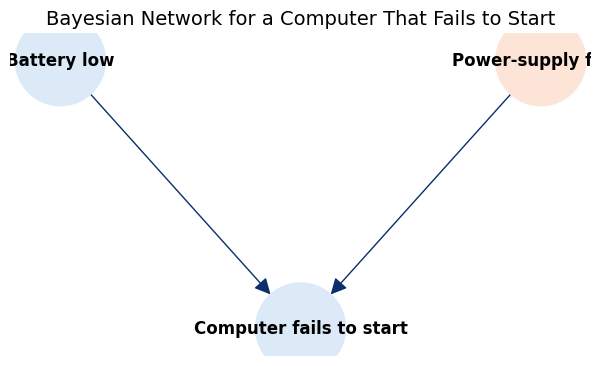

In [149]:
edges = [
    ("Battery low", "Computer fails to start"),
    # Add the edge from "Power-supply fault" to "Computer fails to start".
    ("Power-supply fault", "Computer fails to start"),
]

required_edge = ("Power-supply fault", "Computer fails to start")
network_complete = required_edge in edges
network_status = None if len(edges) == 1 else network_complete

graph = nx.DiGraph(edges)
positions = {
    "Battery low": (-1, 1),
    "Power-supply fault": (1, 1),
    "Computer fails to start": (0, 0),
}

if network_complete:
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    nx.draw_networkx(
        graph,
        pos=positions,
        node_color=[LIGHT_BLUE, LIGHT_BLUE, "#FCE4D6"],
        node_size=4200,
        edge_color=NAVY,
        font_weight="bold",
        arrowsize=24,
        ax=ax,
    )
    ax.set_title("Bayesian Network for a Computer That Fails to Start")
    ax.axis("off")
    plt.show()


### Interpretation

Conditional dependency in a Bayesian network represents a probabilistic association or predictive relationship between variables based on observational data, whereas a causal claim asserts that actively manipulating one variable (such as replacing a battery) will directly produce a physical change in the other variable.

# Naïve Bayesian Learning Model

For a class $(C)$ and features $(X=(x_1,\ldots,x_n))$, Naïve Bayes uses:

$$
P(X\mid C)=\prod_{i=1}^{n}P(x_i\mid C)
$$

and predicts:

$$
\hat C=\arg\max_C P(C)\prod_{i=1}^{n}P(x_i\mid C).
$$


The term "naïve" refers to the assumption that all features are conditionally independent given the class, which is often not true in practice. However, this simplification allows for efficient computation and often yields good classification performance.

### Dataset Behind the Manual Example

> **Problem description.** Construct a concrete dataset whose class frequencies and word frequencies produce the probabilities used in the manual email-classification example. Each email has two binary features: `Free = 1` if it contains “Free” and `Win = 1` if it contains “Win”. The class is either Spam or Not Spam.

The following grouped dataset represents 1,000 emails:

| Class | Free | Win | Number of emails |
|---|---:|---:|---:|
| Spam | 1 | 1 | 180 |
| Spam | 1 | 0 | 120 |
| Spam | 0 | 1 | 60 |
| Spam | 0 | 0 | 40 |
| Not Spam | 1 | 1 | 3 |
| Not Spam | 1 | 0 | 57 |
| Not Spam | 0 | 1 | 27 |
| Not Spam | 0 | 0 | 513 |
| **Total** |  |  | **1,000** |

Each row groups emails with the same class and the same two feature values. We now calculate every probability in the example directly from these counts.

#### Step 1 — Calculate the class priors

The number of Spam emails is:

$$
N_{Spam}=180+120+60+40=400.
$$

The number of Not Spam emails is:

$$
N_{NotSpam}=3+57+27+513=600.
$$

Therefore:

$$
P(Spam)=\frac{400}{1000}=0.40,
\qquad
P(NotSpam)=\frac{600}{1000}=0.60.
$$

These are the **class priors** because they describe the class proportions before examining the words in a new email.

#### Step 2 — Calculate ($P(Free\mid C)$)

Among the 400 Spam emails, the emails containing “Free” are the two rows with `Free = 1`:

$$
N_{Free,Spam}=180+120=300.
$$

Thus:

$$
P(Free\mid Spam)
=\frac{N_{Free,Spam}}{N_{Spam}}
=\frac{300}{400}
=0.75.
$$

Among the 600 Not Spam emails, the number containing “Free” is:

$$
N_{Free,NotSpam}=3+57=60.
$$

Therefore:

$$
P(Free\mid NotSpam)
=\frac{N_{Free,NotSpam}}{N_{NotSpam}}
=\frac{60}{600}
=0.10.
$$

#### Step 3 — Calculate ($P(Win\mid C)$)

Among the Spam emails, the rows with `Win = 1` contain:

$$
N_{Win,Spam}=180+60=240
$$

emails. Hence:

$$
P(Win\mid Spam)
=\frac{N_{Win,Spam}}{N_{Spam}}
=\frac{240}{400}
=0.60.
$$

Among the Not Spam emails, the number containing “Win” is:

$$
N_{Win,NotSpam}=3+27=30.
$$

Therefore:

$$
P(Win\mid NotSpam)
=\frac{N_{Win,NotSpam}}{N_{NotSpam}}
=\frac{30}{600}
=0.05.
$$


## 6. Manual Spam Classification

> **Problem description.** A new email contains the words **“Free”** and **“Win”**. The Spam prior is 0.40 and the Not Spam prior is 0.60. The likelihoods are ($P(Free\mid Spam)=0.75$), ($P(Win\mid Spam)=0.60$), ($P(Free\mid NotSpam)=0.10$), and ($P(Win\mid NotSpam)=0.05$). Calculate both class scores, normalize them, and predict the class.


Table of class scores:  

| Quantity | Spam | Not Spam |
|---|---:|---:|
| $P(C)$ | 0.40 | 0.60 |
| $P(Free\mid C)$ | 0.75 | 0.10 |
| $P(Win\mid C)$ | 0.60 | 0.05 |

In [150]:
p_spam = 0.40
p_not_spam = 0.60

# Calculate the two unnormalized scores.
spam_score = p_spam * 0.75 * 0.60
not_spam_score = p_not_spam * 0.10 * 0.05

# Normalize the scores into posterior probabilities.
p_spam_given_features = spam_score / (spam_score + not_spam_score)
p_not_spam_given_features = 1 - p_spam_given_features

# Set this to either "Spam" or "Not Spam".
predicted_class = "Spam" if p_spam_given_features > p_not_spam_given_features else "Not Spam"

pd.DataFrame({
    "Class": ["Spam", "Not Spam"],
    "Score": [spam_score, not_spam_score],
    "Posterior": [p_spam_given_features, p_not_spam_given_features],
}).style.format({
    "Score": "{:.4f}",
    "Posterior": "{:.4f}",
})

,Class,Score,Posterior
0,Spam,0.1800,0.9836
1,Not Spam,0.0030,0.0164


Note that we usually stop when we obtain the score. But if we want to calculate the posterior probabilities, we can normalize the scores:

$$P(Spam\mid Free,Win)=\frac{Score_{Spam}}{Score_{Spam}+Score_{NotSpam}},$$
$$P(NotSpam\mid Free,Win)=\frac{Score_{NotSpam}}{Score_{Spam}+Score_{NotSpam}}.$$

Most of the time, the score is the probability of the class given the features, but it is not a true probability because it does not sum to 1. Normalizing the scores gives us the true posterior probabilities.

## 7. Log Probabilities and Numerical Underflow

> **Problem description.** A text model multiplies 1,000 feature probabilities, each equal to 0.001. Direct multiplication may underflow to zero. Calculate the equivalent log score using a sum of logarithms.

Recall:

$$
\log\left(\prod_i p_i\right)=\sum_i\log p_i.
$$


Numerical underflow occurs when the product of many small probabilities becomes so small that it cannot be represented accurately in the computer's floating-point arithmetic, effectively resulting in a value of zero. Using logarithms transforms the multiplication of probabilities into a summation of their logarithms, which mitigates the risk of underflow and allows for more stable numerical computations.

In [151]:
feature_probabilities = np.full(1_000, 0.001)
direct_product = np.prod(feature_probabilities)

# Calculate the stable log score with np.log and np.sum.
log_score = np.sum(np.log(feature_probabilities))

print("Direct product:", direct_product)
print("Log score:", log_score)

Direct product: 0.0
Log score: -6907.755278982137


### Interpretation

Logarithms preserve ranking because the $\log(x)$ function is strictly monotonic (increasing). If an estimated feature probability is exactly zero, the classifier should apply Laplace or additive smoothing to prevent the entire joint probability from collapsing to zero.

## 8. Laplace Smoothing

> **Problem description.** In the Not Spam class, the word “prize” appears 0 times among 100 total word occurrences. The vocabulary contains 50 distinct words. Calculate the unsmoothed probability and the Laplace-smoothed probability with (alpha=1).

Implement:

$$
P(w\mid C)=\frac{N_{w,C}+\alpha}{N_C+\alpha|V|}.
$$


The $\alpha$ parameter in Laplace smoothing is a small positive constant that is added to the count of each feature to prevent zero probabilities. A common choice for $\alpha$ is 1, which is known as Laplace smoothing. This technique ensures that every possible feature has a non-zero probability, which is particularly important in text classification tasks where unseen words may appear in new documents.

In [152]:
def laplace_probability(
    word_count: int,
    total_count: int,
    vocabulary_size: int,
    alpha: float = 1.0,
) -> float | None:
    """Return an additively smoothed categorical probability.

    Parameters
    ----------
    word_count:
        Number of occurrences of the selected word in the class.
    total_count:
        Total number of word occurrences in the class.
    vocabulary_size:
        Number of distinct words in the vocabulary.
    alpha:
        Additive smoothing strength; ``alpha=1`` is Laplace smoothing.
    """

    # Replace None with the Laplace-smoothing formula.
    return (word_count + alpha) / (total_count + alpha * vocabulary_size)


unsmoothed_probability = 0 / 100
smoothed_probability = laplace_probability(
    word_count=0,
    total_count=100,
    vocabulary_size=50,
    alpha=1,
)

print("Without smoothing:", unsmoothed_probability)
print("With Laplace smoothing:", smoothed_probability)


Without smoothing: 0.0
With Laplace smoothing: 0.006666666666666667


## 9. Choose the Appropriate Naïve Bayes Variant

> **Problem description.** Three AI teams use different feature representations. Select the Naïve Bayes variant that best matches each representation and justify your choice.

1. Classify flowers using continuous sepal and petal measurements -> Use **Gaussian** Naïve Bayes, as it is suitable for continuous features that can be modeled with a normal distribution.

2. Classify documents using word-frequency counts -> Use **Multinomial** Naïve Bayes, as it is designed for discrete count data, such as word frequencies in text classification tasks.

3. Classify messages using binary indicators for whether selected words appear -> Use **Bernoulli** Naïve Bayes, as it is appropriate for binary/boolean features, indicating the presence or absence of specific words in text classification tasks.


## 10. Train a Small Spam Filter

> **Problem description.** You are given 12 labeled email snippets—6 Spam and 6 Not Spam. Train a Multinomial Naïve Bayes model on word-count features, predict four new messages, and inspect the predicted probabilities.

In real -world applications, you would typically use a larger dataset to train the model and evaluate its performance on a separate test set. However, for this exercise, we will focus on the training and prediction process using the provided small dataset.


In [153]:
train_texts = [
    "free prize win now",
    "claim your free reward",
    "winner cash offer",
    "limited offer click now",
    "win money free bonus",
    "exclusive deal claim prize",
    "project meeting tomorrow",
    "please review the report",
    "lunch at noon with the team",
    "family dinner tonight",
    "schedule class discussion",
    "notes from today's lecture",
]
train_labels = np.array(["Spam"] * 6 + ["Not Spam"] * 6)

test_texts = [
    "free prize win",
    "project meeting notes",
    "limited class offer",
    "family dinner tonight",
]

# Create CountVectorizer(lowercase=True).
vectorizer = CountVectorizer(lowercase=True)

# Fit the vectorizer and transform train_texts.
X_train = vectorizer.fit_transform(train_texts)

# Create MultinomialNB(alpha=1.0) and fit it.
spam_model = MultinomialNB(alpha=1.0)
spam_model.fit(X_train, train_labels)

# Transform test_texts, then calculate predictions and probabilities.
X_test = vectorizer.transform(test_texts)
predictions = spam_model.predict(X_test)
probabilities = spam_model.predict_proba(X_test)

if predictions is None or probabilities is None:
    print("○ Pending: train the model and predict the test messages.")
else:
    result_table = pd.DataFrame({"Email": test_texts, "Prediction": predictions})
    for class_index, class_name in enumerate(spam_model.classes_):
        result_table[f"P({class_name})"] = probabilities[:, class_index]
    display(result_table.style.format({"P(Not Spam)": "{:.2%}", "P(Spam)": "{:.2%}"}))


,Email,Prediction,P(Not Spam),P(Spam)
0,free prize win,Spam,2.70%,97.30%
1,project meeting notes,Not Spam,88.89%,11.11%
2,limited class offer,Spam,25.00%,75.00%
3,family dinner tonight,Not Spam,88.89%,11.11%


In [154]:
model_ready = (
    vectorizer is not None
    and X_train is not None
    and spam_model is not None
    and predictions is not None
    and probabilities is not None
)
pipeline_started = any(
    item is not None
    for item in [vectorizer, X_train, spam_model, X_test, predictions, probabilities]
)

### Analysis

1. **Most ambiguous test message:** *"limited class offer"* with $P(\text{Spam}) = 75.00\%$ and $P(\text{Not Spam}) = 25.00\%$, which is closest to a 50/50 split compared to the others.
2. **Changing alpha from 1.0 to 0.1:** The model's predictions remain identical, but confidence values become much more extreme (closer to $0\%$ or $100\%$) because there is less smoothing.
3. **Reliability limit:** The tiny training set of only 12 examples cannot capture realistic word distributions, leading to highly skewed and overconfident probabilities that do not generalize to the real world.

## 11. Correlated Features and Overconfidence

> **Problem description.** A model observes the word “Free” once. A second model receives two perfectly duplicated copies of the same signal but treats them as conditionally independent. Compare the predicted Spam probabilities and explain why the second model becomes overconfident.

Dataset: Spam Detection

Sample | Contains “Free” | Contains Link| Label
|---|---:|---:|---:
1	| 1	| 1	| Spam
2	| 1	| 0	| Spam
3	| 1	| 1	| Not Spam
4	| 0	| 1	| Not Spam
5	| 0	| 0	| Not Spam

Feature interpretation:

- Contains “Free”: 1 if the message contains the word “Free”; otherwise 0.
- Contains Link: 1 if the message contains a link; otherwise 0.
- Label: Spam or Not Spam.

To demonstrate the problem, create a second feature, Contains “Free” (Duplicate), that copies the first feature exactly.

Sample | Contains “Free” | Duplicate “Free” | Contains Link | Label
|---|---:|---:|---:|---:
1 | 1 | 1 | 1 | Spam
2 | 1 | 1 | 0 | Spam
3 | 1 | 1 | 1 | Not Spam
4 | 0 | 0 | 1 | Not Spam
5 | 0 | 0 | 0 | Not Spam

The two “Free” features contain exactly the same information. However, a Naive Bayes classifier may treat them as two independent pieces of evidence, effectively counting the same signal twice.



For example, if the first model predicts $P(\text{Spam}\mid \text{Free}) = 0.75$, the second model, treating the two occurrences of "Free" as independent, would calculate:

$$P(\text{Spam}\mid \text{Free, Free}) = \frac{P(\text{Free}\mid \text{Spam})^2 P(\text{Spam})}{P(\text{Free, Free})}$$

Use a Spam prior of $0.40$, with ($P(Free\mid Spam)=0.75$) and ($P(Free\mid NotSpam)=0.10$).


In [155]:
def two_class_posterior(
    prior_spam: float,
    p_features_given_spam: list[float],
    p_features_given_ham: list[float],
) -> float:
    """Calculate the Spam posterior from two unnormalized Naïve Bayes scores."""

    score_spam = prior_spam * np.prod(p_features_given_spam)
    score_ham = (1 - prior_spam) * np.prod(p_features_given_ham)
    return float(score_spam / (score_spam + score_ham))

In [156]:
posterior_one_signal = two_class_posterior(
    prior_spam=0.40,
    p_features_given_spam=[0.75],
    p_features_given_ham=[0.10],
)

posterior_duplicated_signal = two_class_posterior(
    prior_spam=0.40,
    p_features_given_spam=[0.75, 0.75],
    p_features_given_ham=[0.10, 0.10],
)

print("One signal:", posterior_one_signal)
print("Duplicated signal:", posterior_duplicated_signal)

One signal: 0.8333333333333334
Duplicated signal: 0.974025974025974


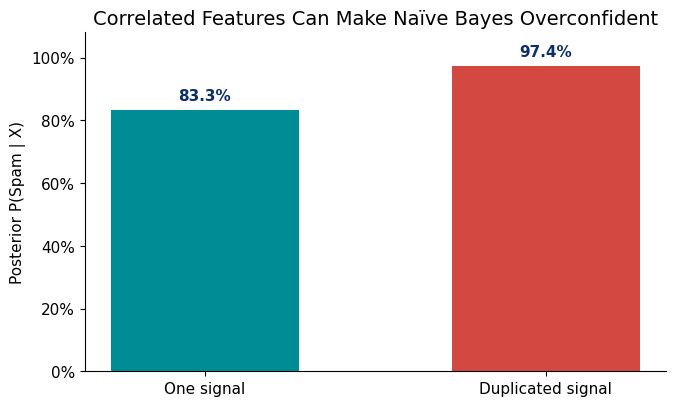

In [157]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
bars = ax.bar(
    ["One signal", "Duplicated signal"],
    [posterior_one_signal, posterior_duplicated_signal],
    color=[TEAL, RED],
    width=0.55,
)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Posterior P(Spam | X)")
ax.set_title("Correlated Features Can Make Naïve Bayes Overconfident")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")

for bar, value in zip(bars, [posterior_one_signal, posterior_duplicated_signal]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.03,
            f"{value:.1%}", ha="center", fontweight="bold", color=NAVY)

plt.show()

### Interpretation

The extra confidence is misleading because Naïve Bayes assumes features are conditionally independent. When two highly correlated features are treated as independent, the model double-counts the evidence. A real example is having the words "Millions" and "Dollars" in the same spam email, which carry almost identical predictive information.

# Inferred Causation

Inferred causation is the process of drawing conclusions about causal relationships based on observed data. It is important to distinguish between correlation and causation, as a strong association between two variables does not necessarily imply that one causes the other.

Here are three key distinctions to keep in mind:

- **Association:** What do we learn about (Y) when we observe (X=x)?
- **Prediction:** Can (X) help forecast (Y)?
- **Causation:** Would deliberately changing (X) change (Y)?

A strong association or accurate prediction does not, by itself, identify a causal effect.


## 12. Ice Cream, Swimming, and Temperature

> **Problem description.** Across 350 simulated summer days, ice cream sales and swimming activity rise together. Temperature influences both variables. Measure the raw association, adjust for temperature, and explain why the raw correlation should not be interpreted as evidence that ice cream sales cause swimming.


In [158]:
# The simulation mechanism is known: temperature is a common cause.
n_days = 350
temperature = rng.uniform(18, 38, n_days)
ice_cream_sales = 25 + 3.0 * (temperature - 18) + rng.normal(0, 8, n_days)
swimming_activity = 12 + 2.2 * (temperature - 18) + rng.normal(0, 7, n_days)

summer_data = pd.DataFrame({
    "Temperature": temperature,
    "Ice cream sales": ice_cream_sales,
    "Swimming activity": swimming_activity,
})

summer_data.head().style.format({
    "Temperature": "{:.4f}",
    "Ice cream sales": "{:.4f}",
    "Swimming activity": "{:.4f}",
}
)

,Temperature,Ice cream sales,Swimming activity
0,33.4791,73.9334,56.5427
1,26.7776,60.5752,28.0988
2,35.1720,81.3860,46.8049
3,31.9474,48.5118,44.8827
4,19.8835,33.0856,14.4235


In [159]:
def partial_correlation(
    x: np.ndarray,
    y: np.ndarray,
    z: np.ndarray,
) -> float | None:
    """Calculate the correlation of x and y after linear adjustment for z.

    Parameters
    ----------
    x, y:
        Variables whose adjusted correlation is required.
    z:
        Potential confounder to regress out of both x and y.
    """

    
    # 1. Reshape z into a two-dimensional predictor.
    # 2. Regress x on z and calculate residual_x.
    # 3. Regress y on z and calculate residual_y.
    # 4. Return the correlation between the two residual vectors.
    z_2d = np.asarray(z).reshape(-1, 1)
    residual_x = np.asarray(x) - LinearRegression().fit(z_2d, x).predict(z_2d)
    residual_y = np.asarray(y) - LinearRegression().fit(z_2d, y).predict(z_2d)
    return float(np.corrcoef(residual_x, residual_y)[0, 1])


# Calculate the raw correlation.
raw_correlation = np.corrcoef(ice_cream_sales, swimming_activity)[0, 1]

# Call partial_correlation to adjust for temperature.
temperature_adjusted_correlation = partial_correlation(
    ice_cream_sales,
    swimming_activity,
    temperature,
)

print("Raw correlation:", raw_correlation)
print("Correlation after controlling for temperature:", temperature_adjusted_correlation)

Raw correlation: 0.7873088729266537
Correlation after controlling for temperature: 0.003503736614574792


### Graph and interpretation tasks

1. Create a scatter plot of ice cream sales against swimming activity and color the points by temperature.
2. Draw the causal hypothesis ($Temperature\rightarrow IceCreamSales$) and ($Temperature\rightarrow SwimmingActivity$).
3. Explain why controlling for temperature changes the correlation.
4. State one limitation of using partial correlation as evidence about causation.


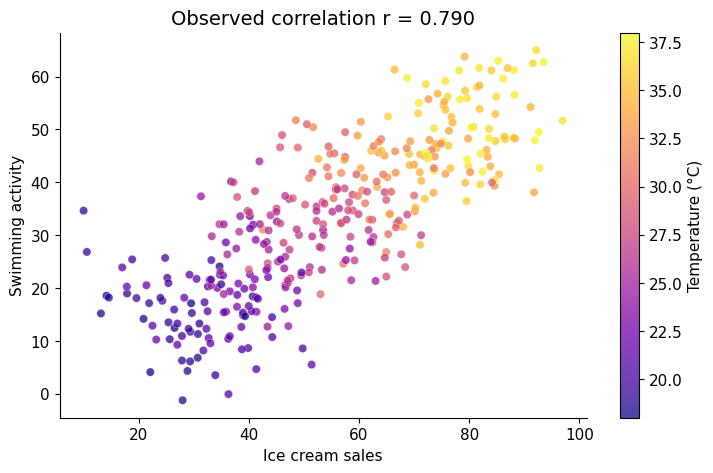

In [160]:
# Generate data from a known mechanism: temperature is the common cause.
n_days = 350
temperature = rng.uniform(18, 38, n_days)
ice_cream_sales = 25 + 3.0 * (temperature - 18) + rng.normal(0, 8, n_days)
swimming_activity = 12 + 2.2 * (temperature - 18) + rng.normal(0, 7, n_days)

summer_data = pd.DataFrame({
    "Temperature": temperature,
    "Ice cream sales": ice_cream_sales,
    "Swimming activity": swimming_activity,
})

raw_correlation = summer_data["Ice cream sales"].corr(summer_data["Swimming activity"])

fig, ax = plt.subplots(figsize=(8.5, 5))
scatter = ax.scatter(
    ice_cream_sales,
    swimming_activity,
    c=temperature,
    cmap="plasma",
    alpha=0.75,
    edgecolor="white",
    linewidth=0.3,
)
ax.set_xlabel("Ice cream sales")
ax.set_ylabel("Swimming activity")
ax.set_title(f"Observed correlation r = {raw_correlation:.3f}")
fig.colorbar(scatter, ax=ax, label="Temperature (°C)")
plt.show()

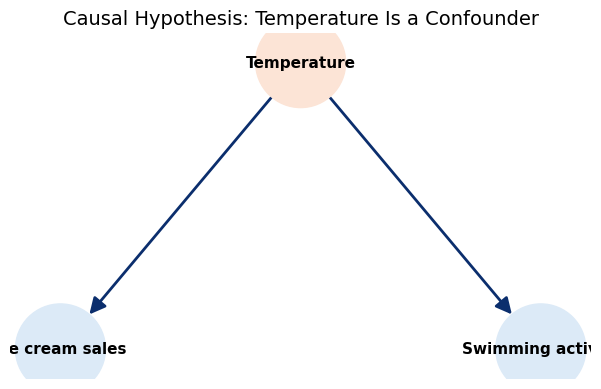

In [161]:
# Draw the causal hypothesis that generated the simulated data.
causal_graph = nx.DiGraph([
    ("Temperature", "Ice cream sales"),
    ("Temperature", "Swimming activity"),
])
causal_positions = {
    "Temperature": (0, 1),
    "Ice cream sales": (-1, 0),
    "Swimming activity": (1, 0),
}

fig, ax = plt.subplots(figsize=(7.5, 4.5))
nx.draw_networkx(
    causal_graph,
    pos=causal_positions,
    ax=ax,
    node_color=["#FCE4D6", LIGHT_BLUE, LIGHT_BLUE],
    node_size=4200,
    edge_color=NAVY,
    font_size=11,
    font_weight="bold",
    arrowsize=24,
    width=2,
)
ax.set_title("Causal Hypothesis: Temperature Is a Confounder")
ax.axis("off")
plt.show()

### Graph and interpretation tasks

1. **Scatter plot and causal graph:** Completed in the cells below.
2. **Why controlling changes correlation:** Controlling for temperature removes the variation caused by the shared external confounder. Once this common cause is held constant, the residual association drops to zero.
3. **Limitation of partial correlation:** Partial correlation only controls for known, measured linear confounders; it cannot rule out unmeasured, non-linear, or reverse-causal relationships.

In [162]:
n_students = 2_500
# Re-initialize the generator to ensure exact replication of the expected dataset
rng = np.random.default_rng(SEED)
motivation = rng.normal(0, 1, n_students)
prior_ability = rng.normal(0, 1, n_students)

online_usage = (
    5
    + 1.3 * motivation
    + 0.9 * prior_ability
    + rng.normal(0, 1.1, n_students)
)
online_usage = np.clip(online_usage, 0, None)

true_causal_effect = 1.5
exam_grade = (
    60
    + true_causal_effect * online_usage
    + 5.0 * motivation
    + 6.0 * prior_ability
    + rng.normal(0, 4, n_students)
)

student_data = pd.DataFrame({
    "online_usage": online_usage,
    "motivation": motivation,
    "prior_ability": prior_ability,
    "exam_grade": exam_grade,
})

display(student_data.head(20).style.format(
    {"online_usage": "{:.2%}",
    "motivation": "{:.2%}",
    "prior_ability": "{:.2%}",
    "exam_grade": "{:.2%}", }                               
))

,online_usage,motivation,prior_ability,exam_grade
0,561.02%,30.47%,55.31%,7700.17%
1,354.26%,-104.00%,24.89%,5291.87%
2,611.71%,75.05%,100.87%,7676.07%
3,713.01%,94.06%,48.45%,7808.62%
4,381.77%,-195.10%,121.77%,6419.97%
5,238.49%,-130.22%,91.94%,5967.72%
6,471.90%,12.78%,152.17%,6949.61%
7,537.90%,-31.62%,35.88%,6543.56%
8,489.61%,-1.68%,90.53%,6969.66%
9,394.69%,-85.30%,-30.71%,5672.00%


In [163]:
# Fit a regression using only online_usage to predict exam_grade.
unadjusted_model = LinearRegression().fit(
    student_data[["online_usage"]],
    student_data["exam_grade"],
)

# Fit a regression using online_usage, motivation, and prior_ability.
adjusted_model = LinearRegression().fit(
    student_data[["online_usage", "motivation", "prior_ability"]],
    student_data["exam_grade"],
)

# Extract the online_usage coefficient from each model.
unadjusted_effect = unadjusted_model.coef_[0]
adjusted_effect = adjusted_model.coef_[0]

effect_table = pd.DataFrame({
    "Estimate": ["Unadjusted", "Adjusted", "Simulation truth"],
    "Grade increase per usage unit": [
        unadjusted_effect,
        adjusted_effect,
        true_causal_effect,
    ],
})
display(effect_table.style.format(
    {"Grade increase per usage unit": "{:.2f}"}
)
)

,Estimate,Grade increase per usage unit
0,Unadjusted,4.72
1,Adjusted,1.53
2,Simulation truth,1.50


### Causal reasoning questions

1. **Unadjusted model overstatement:** It suffers from confounding bias; motivated and high-ability students both use the system more and get higher grades anyway.
2. **Backdoor paths:**
   - $\text{online\_usage} \leftarrow \text{motivation} \rightarrow \text{exam\_grade}$
   - $\text{online\_usage} \leftarrow \text{prior\_ability} \rightarrow \text{exam\_grade}$
3. **Proving causation:** No. Observational adjustments cannot rule out other unobserved confounders (e.g., parental support, sleep hours) or reverse causation.
4. **Ethical design:** Conduct a randomized controlled trial (RCT) where access to a premium feature of the online-learning system is randomly assigned via lottery to a subset of interested students.

# Integrated Challenge

This section connects Bayesian diagnosis with causal reasoning.


## Computer Fault Diagnosis

> **Problem description.** A computer is overheating and shutting down unexpectedly. One hypothesis is that the cooling fan has failed. Before observing overheating, the probability of fan failure is 10%. Overheating occurs in 90% of computers with a failed fan and in 20% of computers whose fan is working.

### Part A — Bayesian diagnosis

Calculate the posterior probability of fan failure after observing overheating.

### Part B — Causal evaluation

The posterior supports a diagnostic hypothesis, but it does not prove that fan failure caused the overheating in this particular computer. Identify two alternative explanations and propose one test or intervention that would help distinguish them.


In [164]:
p_fan_failure = 0.10
p_overheating_given_failure = 0.90
p_overheating_given_working_fan = 0.20

# Calculate the evidence and posterior.
p_overheating = p_overheating_given_failure * p_fan_failure + p_overheating_given_working_fan * (1 - p_fan_failure)
p_failure_given_overheating = p_overheating_given_failure * p_fan_failure / p_overheating

print("P(overheating) =", p_overheating)
print("P(fan failure | overheating) =", p_failure_given_overheating)

P(overheating) = 0.27
P(fan failure | overheating) = 0.33333333333333337


### Causal analysis

- **Alternative explanation 1:** Dust buildup is causing both the fan to struggle/fail and the CPU to overheat independently.
- **Alternative explanation 2:** A intensive background software process is overloading the CPU (causing overheating), while the fan failure is a separate, unrelated physical issue.
- **Proposed test or intervention:** Manually spin the fan or replace it with a known working fan to see if the overheating stops.
- **Why the posterior alone is not causal proof:** The posterior probability represents a statistical correlation under passive observation, but it does not tell us what would happen if we intervened directly on the system.

# Recap

Working through this notebook highlighted how easily raw correlation can mislead us when strong confounders are present, as seen in the temperature and student motivation examples. It clarified that Naïve Bayes is highly sensitive to feature redundancy, which results in overconfident predictions when the independence assumption is violated. Finally, learning to calculate stable log-probabilities underscored the importance of numerical stability in machine learning. Ultimately, it showed that true causal understanding requires active intervention or careful adjustment rather than simple association.